[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_diffgeomcurves.ipynb)


# Differential geometry of curves

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display


def animate_parameter(draw,minimum,maximum,value,step,label):
    draw(value)
    slider=widgets.FloatSlider(value=value,min=minimum,max=maximum,step=step,
                               description=label,continuous_update=False)
    play=widgets.Play(value=0,min=0,max=int(round((maximum-minimum)/step)),step=1,interval=120,repeat=False)
    def advance(change):
        slider.value=min(maximum,minimum+change['new']*step)
    play.observe(advance,names='value')
    view=widgets.interactive_output(lambda parameter: draw(parameter),{'parameter':slider})
    display(widgets.VBox([widgets.HBox([play,slider]),view]))
    return slider,play,view

## Geometry of curves and kinematics

A natural way to describe a curve is kinematic: specify its position vector $\mathbf{r}\left(t\right)$ as a function of a parameter called time. We require the velocity $\mathbf{v}\left(t\right)=d\mathbf{r}/dt$ to exist. At points where the velocity is nonzero, the tangent is well defined; these are called regular points. A zero velocity may occur at a turning point. A smooth, monotonic reparameterization $t\mapsto u\left(t\right)$ with $u^{\prime}\left(t\right)>0$ changes the rate of motion along the curve while preserving its geometric shape. A distinguished geometric parameter is the arc length $s$. It agrees with time for motion at unit speed, $\left|\mathbf{v}\right|=1$. The acceleration is:

$$
\mathbf{a}=\frac{d \mathbf{v}}{d t}\tag{1}
$$

As we know from kinematics, the acceleration has tangential and normal (centripetal) components:

$$
\mathbf{a}\mathbf{=}\frac{dv}{dt}\mathbf{\tau }\mathbf{+}{v}^{2} \frac{d\mathbf{\tau }}{ds}={a}_{\tau }\mathbf{\tau }+{a}_{n}\mathbf{n}\tag{2}
$$

Here $\mathbf{n}$ is the unit normal vector, perpendicular to the unit tangent $\boldsymbol{\tau}$.

The derivative of a vector of constant length is perpendicular to that vector. Its change can therefore be described as a rotation about an instantaneous axis. In particular, this applies to the unit tangent:

$$
\frac{d\mathbf{\tau }}{ds} =k \mathbf{n}\tag{3}
$$

Here $k$ is the curvature and $R=1/k$ is the radius of curvature. Similarly,

$$
\frac{d\mathbf{n}}{ds}\perp  \mathbf{n}\tag{4}
$$

which, for a plane curve, gives

$$
\frac{d\mathbf{n}}{ds}= -k\mathbf{\tau }\tag{5}
$$

## Frenet–Serret formulas and the Darboux vector

A curve defines a moving orthonormal frame: the tangent $\boldsymbol{\tau}$, normal $\mathbf{n}$, and binormal $\mathbf{b}=\boldsymbol{\tau}\times\mathbf{n}$. As we move along the curve, this frame rotates about an instantaneous axis described by the Darboux vector $\mathbf{D}$. For a plane curve, $\mathbf{D}$ is perpendicular to the plane of motion, with direction given by the right-hand rule. We can write:

$$
\frac{d\mathbf{\tau }}{ds}=\mathbf{D} \times \mathbf{\tau } = k \mathbf{n},\frac{d\mathbf{n}}{ds}=\mathbf{D} \times \mathbf{n} ,\frac{d\mathbf{b}}{ds}=\mathbf{D} \times \mathbf{b}\\ \frac{d\mathbf{b}}{ds}=\mathbf{\frac{d\mathbf{\tau }}{ds}}\times \mathbf{n}\mathbf{+} \mathbf{\tau }\times \mathbf{\frac{d \mathbf{n}}{ds}}\tag{6}
$$

$$
\mathbf{D}\mathbf{ }\mathbf{=}\mathbf{ }k \mathbf{b}+\gamma  \mathbf{\tau }\mathbf{ }\mathbf{\Rightarrow }\mathbf{ }{\mathbf{D}}^{2}={k}^{2}+{\gamma }^{2}\tag{7}
$$

The quantity $\gamma$ is called torsion. For a plane curve, $\gamma=0$ and $\left|\mathbf{D}\right|=k$, consistent with interpreting $\mathbf{D}$ as an angular velocity per unit arc length.

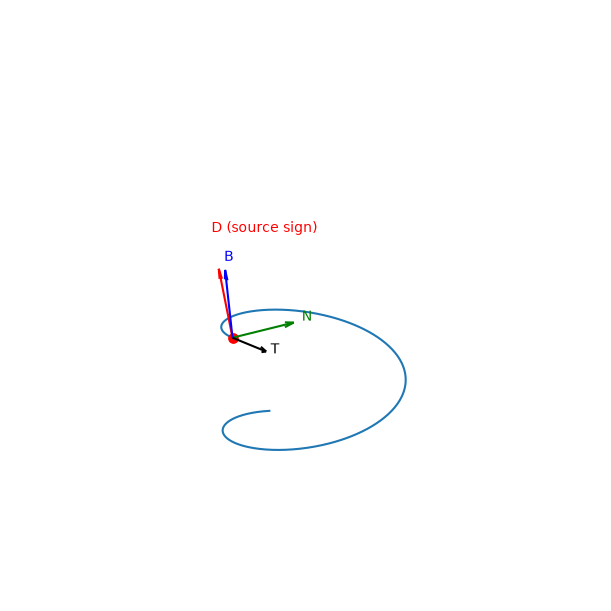

In [2]:
def helix_frame(t):
    r=np.array([np.cos(t),np.sin(t),0.2*t])
    tangent=np.array([-np.sin(t),np.cos(t),0.2])/np.sqrt(1.04)
    normal=np.array([-np.cos(t),-np.sin(t),0.0])
    binormal=np.cross(tangent,normal)
    curvature=1/1.04
    torsion=-0.2/1.04  # The source uses r‴ dot (r'' cross r'), with this sign.
    darboux=curvature*binormal+torsion*tangent
    return r,tangent,normal,binormal,darboux

def show_helix(t0):
    time=np.linspace(-np.pi/2,t0,500)
    r,tangent,normal,binormal,darboux=helix_frame(t0)
    fig=plt.figure(figsize=(6,6),layout='constrained'); ax=fig.add_subplot(projection='3d')
    ax.plot(np.cos(time),np.sin(time),0.2*time)
    ax.scatter(*r,color='red',s=45)
    for direction,label,color in [(tangent,'T','black'),(normal,'N','green'),(binormal,'B','blue'),
                                   (darboux/np.linalg.norm(darboux),'D (source sign)','red')]:
        ax.quiver(*r,*(0.75*direction),color=color,arrow_length_ratio=0.15)
        ax.text(*(r+(1.15 if color=='red' else 0.85)*direction),label,color=color)
    ax.set(xlim=(-1.5,1.5),ylim=(-1.5,1.5),zlim=(-1,4)); ax.set_box_aspect((3,3,5))
    ax.view_init(25,60); ax.axis('off'); plt.show()
helix_controls=animate_parameter(show_helix,-np.pi/2.1,5*np.pi,2*np.pi,0.1,'t')

In this notation, each entry in parentheses represents a $3\times3$ block, and the full matrix is $9\times9$. Since the frame spans the space, no further independent relations are needed. The curvature $k\left(s\right)$ and torsion $\gamma\left(s\right)$ determine the shape of a regular curve; this is the fundamental theorem of curve theory. A curve of zero curvature is a straight line (consider what happens to the normal and torsion). Constant nonzero curvature and constant torsion describe a helix; with zero torsion, the corresponding plane curve is a circle.

Let us derive curvature and torsion for a parametric curve. Starting from the kinematic relations:

$$
\frac{d \mathbf{r}}{d t}=v\mathbf{\tau }\mathbf{,}\mathbf{ }\frac{{d}^{2}\mathbf{r}}{d {t}^{2}}=\frac{dv}{dt}\mathbf{\tau }\mathbf{+}k\mathbf{ }{v}^{2}\mathbf{n}\tag{8}
$$

and using the definition of the binormal vector, we obtain

$$
\frac{d \mathbf{r}}{d t}\times \frac{{d}^{2}\mathbf{r}}{d {t}^{2}}=k\mathbf{ }{v}^{3}\mathbf{b}\\ \frac{{d}^{3}\mathbf{r}}{d {t}^{3}}=\frac{{d}^{3}v}{d {t}^{3}}\mathbf{\tau }\mathbf{+}\left(3k v \frac{dv}{dt}+{v}^{3}\frac{dk}{ds}\right)\mathbf{n}\mathbf{+}k {v}^{3}\left(-k \mathbf{\tau }+\gamma  \mathbf{b}\right)\tag{9}
$$

and therefore

$$
\frac{d \mathbf{r}}{d t}\times \frac{{d}^{2}\mathbf{r}}{d {t}^{2}}=k\mathbf{ }{v}^{3}\mathbf{b}\\ k\mathbf{=}\frac{\left|\mathbf{a}\times \mathbf{v}\right|}{{v}^{3}},\gamma =\frac{\mathbf{\frac{d\mathbf{a}}{dt}}\mathbf{\cdot }\left(\mathbf{a}\times \mathbf{v}\right)}{\left|\mathbf{a}\times \mathbf{v}\right|^{2}}\tag{10}
$$

In [3]:
t,s=sp.symbols('t s',real=True)
speed=sp.Function('v')(t)
kappa=sp.Function('k')(s); gamma=sp.Function('gamma')(s)
T,N,B=sp.symbols('T N B',commutative=True)
r=sp.Function('r')
r1t=speed*sp.diff(r(s),s)
r2t=sp.diff(speed,t)*T+speed**2*kappa*N
r3t=(sp.diff(speed,t,2)-speed**3*kappa**2)*T + (3*speed*sp.diff(speed,t)*kappa+speed**3*sp.diff(kappa,s))*N + speed**3*kappa*gamma*B
display(r1t,r2t,r3t)

v(t)*Derivative(r(s), s)

N*k(s)*v(t)**2 + T*Derivative(v(t), t)

B*gamma(s)*k(s)*v(t)**3 + N*(3*k(s)*v(t)*Derivative(v(t), t) + v(t)**3*Derivative(k(s), s)) + T*(-k(s)**2*v(t)**3 + Derivative(v(t), (t, 2)))

The curvature $k$ is nonnegative by definition, whereas the torsion $\gamma$ can have either sign. What geometric difference does the sign describe? The formulas involve derivatives of the position vector up to third order. The original lecture then infers that a particle’s equations of motion must also be of order no higher than three; this inference needs a separate dynamical argument.

Consider a neighbourhood of a regular point:

$$
\mathbf{r}\left(s\right)={r}_{0}+s \dot{\mathbf{r}}\left(0\right) +\frac{1}{2}{s}^{2} \ddot{\mathbf{r}}\left(0\right)+\frac{1}{3!}{s}^{3}\dddot{\mathbf{r}}\left(0\right)+o\left({s}^{3}\right),\\ \dot{\mathbf{r}}\left(0\right)={\mathbf{\tau }}_{0}, \ddot{\mathbf{r}}\left(0\right)=k\mathbf{ }{\mathbf{n}}_{0}, \dddot{\mathbf{r}}\left(0\right)=k\mathbf{ }{\mathbf{n}}_{0}-{k}^{2}{\mathbf{\tau }}_{0}+k\gamma  {\mathbf{b}}_{0}\\ \mathbf{r}\left(s\right)=\left(s+...\right){\mathbf{\tau }}_{0}+\left(\frac{1}{2}{s}^{2}{k}_{0}+...\right)\mathbf{ }{\mathbf{n}}_{0}+\left(\frac{{s}^{3}}{6}k\gamma +...\right){\mathbf{b}}_{0}\tag{11}
$$

This expansion describes the local shape of the curve. Its projections onto the coordinate planes are shown below:

In [4]:
r1s=sp.diff(r(s),s)
r2s=kappa*N
r3s=-kappa**2*T+sp.diff(kappa,s)*N+kappa*gamma*B
display(r1s,r2s,r3s)

Derivative(r(s), s)

N*k(s)

B*gamma(s)*k(s) + N*Derivative(k(s), s) - T*k(s)**2

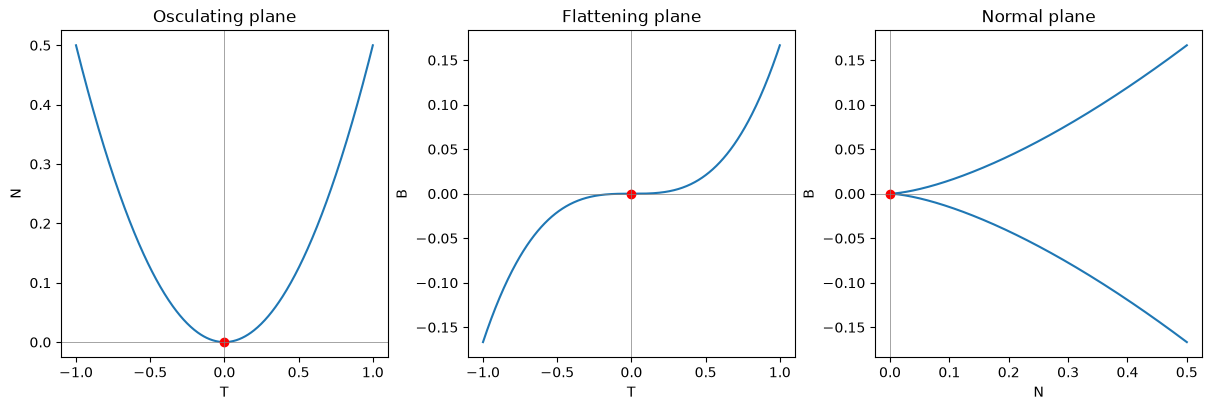

In [5]:
arc=np.linspace(-1,1,501)
fig,axes=plt.subplots(1,3,figsize=(12,4),layout='constrained')
for ax,x,y,title,xlabel,ylabel in [
    (axes[0],arc,arc**2/2,'Osculating plane','T','N'),
    (axes[1],arc,arc**3/6,'Flattening plane','T','B'),
    (axes[2],arc**2/2,arc**3/6,'Normal plane','N','B')]:
    ax.plot(x,y); ax.plot(0,0,'ro'); ax.set(xlabel=xlabel,ylabel=ylabel,title=title,box_aspect=1)
    ax.axhline(0,color='gray',lw=0.5); ax.axvline(0,color='gray',lw=0.5)
plt.show()

## Evolutes and parallel curves

A curve naturally defines several related curves. A parallel curve consists of points displaced by a fixed distance $p$ along the normal:

$$
\mathbf{p}\left(s\right)= \mathbf{r}\left(s\right) +p \mathbf{n}\left(s\right)\tag{12}
$$

A parallel curve can represent a propagating wavefront in a homogeneous, isotropic medium, generated by point sources along the original curve. It is an envelope of a family of circles.

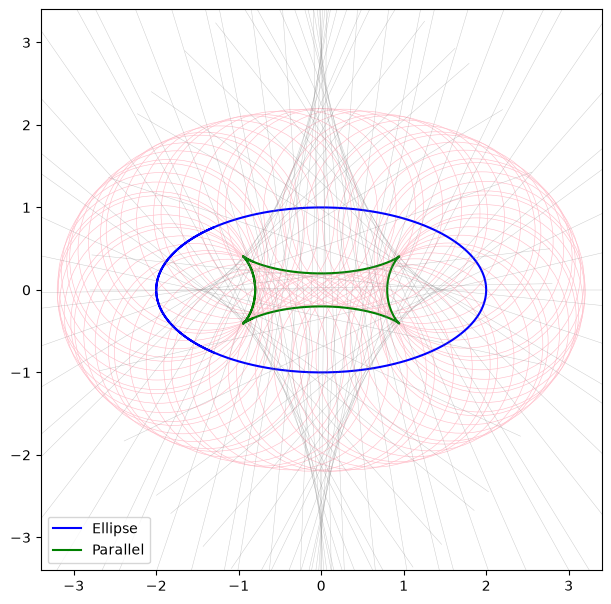

In [6]:
def ellipse_geometry(t):
    t=np.asarray(t)
    position=np.array([2*np.cos(t),np.sin(t)])
    normal=np.array([-np.cos(t),-2*np.sin(t)])/np.sqrt(np.cos(t)**2+4*np.sin(t)**2)
    return position,normal

def show_ellipse_offset(d):
    t=np.linspace(-4,4,700)
    r,n=ellipse_geometry(t)
    fig,ax=plt.subplots(figsize=(6,6),layout='constrained')
    ax.plot(*r,color='blue',label='Ellipse'); ax.plot(*(r+d*n),color='green',label='Parallel')
    centers,normals=ellipse_geometry(np.arange(-4*np.pi,4*np.pi,0.4))
    for center,normal in zip(centers.T,normals.T):
        line=center[:,None]+d*normal[:,None]*np.array([-4,4])
        ax.plot(*line,color='gray',lw=0.35,alpha=0.4)
        ax.add_patch(plt.Circle(center,d,fill=False,color='pink',lw=0.45))
    ax.set(xlim=(-3.4,3.4),ylim=(-3.4,3.4),aspect='equal'); ax.legend(); plt.show()
offset_controls=animate_parameter(show_ellipse_offset,0,4,1.2,0.05,'d')

Another related curve is the evolute: the locus of centres of curvature.

$$
\mathbf{ev}\left(s\right)= \mathbf{r}\left(s\right) + \frac{\mathbf{n}\left(s\right)}{k\left(s\right)}\tag{13}
$$

For a circle, the evolute reduces to a point. The original curve is an involute of its evolute.

This is not an arc-length parameterization of the evolute: $s$ measures distance along the original curve. The radius of curvature of the original curve can be used as an arc-length parameter of the evolute, locally where it changes monotonically. Imagine unwinding a taut thread from the evolute. Its free end traces the original curve, and the distance travelled along the evolute equals the change in the radius of curvature.

Let us illustrate the construction of the evolute of a parabola.

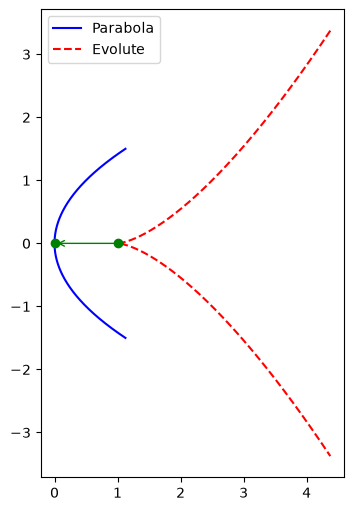

In [7]:
def parabola_geometry(t):
    t=np.asarray(t)
    position=np.array([t*t/2,t])
    normal=np.array([np.ones_like(t),-t])/np.sqrt(1+t*t)
    curvature=(1+t*t)**(-1.5)
    return position,position+normal/curvature

def show_evolute(t0):
    t=np.linspace(-1.5,1.5,501); curve,evolute=parabola_geometry(t)
    point,center=parabola_geometry(t0)
    fig,ax=plt.subplots(figsize=(6,5),layout='constrained')
    ax.plot(*curve,color='blue',label='Parabola'); ax.plot(*evolute,'r--',label='Evolute')
    ax.plot([point[0],center[0]],[point[1],center[1]],'go')
    ax.annotate('',xy=point,xytext=center,arrowprops={'arrowstyle':'->','color':'green'})
    ax.set(aspect='equal'); ax.legend(); plt.show()
evolute_controls=animate_parameter(show_evolute,-1.5,1.5,0,0.1,'t')

[Back to the course contents](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_TOC.ipynb)